# PORTAFOLIO CON ACTIVOS CORRELACIONADOS

### Sacando la caja de herramientas (Librerías)
En esta primera celda nada más importamos lo básico para chambear: numpy y pandas para manejar números y tablas sin sufrir, matplotlib para armar las gráficas, yfinance para conectarnos a Yahoo Finance y bajar precios reales de la bolsa, y un par de funciones estadísticas de scipy (qmc y norm) para generar números aleatorios con esteroides.

In [117]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import qmc, norm



## ELECCIÓN E IMPORTACIÓN DE DATOS
Aquí elegimos a nuestros 4 gallos del portafolio: Nvidia (NVDA), Bimbo (BIMBOA.MX), Cemex (CEMEXCPO.MX) y AstraZeneca (AZN).

Bajamos sus precios de cierre de los últimos 3 años día por día y calculamos sus rendimientos logarítmicos (básicamente cuánto suben o bajan proporcionalmente de un día a otro). Además, como tenemos acciones gringas (en dólares) y mexicanas (en pesos), también descargamos el tipo de cambio dólar-peso (USDMXN=X) y sus rendimientos para poder poner todo en la misma moneda.

In [118]:
tickers = ['NVDA', 'BIMBOA.MX', 'CEMEXCPO.MX', 'AZN']
precios = yf.download(tickers, period='3Y', interval='1d', progress=False)['Close'].dropna()
rend = (np.log(precios)).diff().dropna()
#datos de divisa para estandarizar divisa a USD
fx = yf.download("USDMXN=X", period='3Y',interval = '1d', progress=False)["Close"]
fx_rend = (np.log(fx)).diff().dropna()

$$\text{MXN} = \text{USD} \times \text{Tipo de Cambio (USDMXN)}$$

### Pasando todo a pesos (Precios de arranque)
Para no mezclar dólares con pesos desde el inicio, agarramos el último precio de NVDA y AZN y los multiplicamos por el tipo de cambio reciente. Con eso armamos nuestra lista So, que tiene el precio inicial (de hoy) de las 4 acciones ya estandarizado en pesos mexicanos.

In [119]:
#precios ajustados de arranque (hoy)
precios_USD_MXN =  fx['USDMXN=X'].iloc[-2] * precios[['NVDA','AZN' ]].iloc[-1] #[-2] porque es la cotización de 02-11_2025
So = [precios_USD_MXN['NVDA'],precios['BIMBOA.MX'].iloc[-1], precios['CEMEXCPO.MX'].iloc[-1], precios_USD_MXN['AZN']]

## PARÁMETROS PARA LA SIMULACIÓN
Aquí le sacamos la radiografía a cada acción y al tipo de cambio: calculamos su rendimiento promedio (mus) y su volatilidad o riesgo (sigmas).

Como los datos son diarios pero queremos simular a 1 año completo, los anualizamos: el promedio se multiplica por 252 (los días hábiles que abre la bolsa en un año) y la desviación estándar se multiplica por $\sqrt{252}$.

In [120]:

mus = np.mean(rend, axis = 0) * 252
sigmas = np.std(rend, axis = 0) * np.sqrt(252)
mu_fx = np.array(np.mean(fx_rend, axis = 0) * 252)
sigmas_fx = np.array(np.std(fx_rend, axis = 0) * np.sqrt(252))
fx_so = fx['USDMXN=X'].iloc[-2]
print(sigmas_fx)

[0.10972135]


## PESOS SEGÚN ESCENARIO
Aquí definimos 3 estrategias distintas para repartir nuestro dinero entre las 4 acciones (los famosos pesos $w$ del portafolio):
- p1: Jugársela toda al 100% en la primera acción y 0% en las demás.
- p2: Repartir parejo como buenos amigos (25% en cada una de las 4 acciones).
- p3: Ir escalonado dándole 10%, 20%, 30% y 40% a cada activo.

In [121]:
portafolios = {
    'p1': [1,0,0,0],
    'p2': [.25,.25,.25,.25],
    'p3': [.1,.2,.3,.4],
}

## GENERADOR DE MERCADO
Esta función mercado es nuestro simulador clásico (basado en el Movimiento Browniano Geométrico). Le pasas el precio inicial (S0), el tiempo (T), el rendimiento esperado (r), la volatilidad (sigma), cuántas simulaciones quieres y de cuántos pasos.

Adentro calcula el empujón de tendencia (drift) más el ruido aleatorio del mercado (diffusion * Z), los va acumulando en el tiempo y te regresa todos los caminos de precios simulados.

In [122]:
def mercado(S0, T, r, sigma, num_simulations, num_steps):
    np.random.seed(42)

    dt = T / num_steps
    drift = (r - 0.5 * sigma**2) * dt
    diffusion = sigma * np.sqrt(dt)

    Z = np.random.normal(0, 1, (num_steps, num_simulations))
    log_returns = drift + diffusion * Z

    # Acumular sobre el tiempo
    price_path = S0 * np.exp(np.cumsum(log_returns, axis=0))

    # Tomar el último precio de cada simulación
    return price_path

## PRECIOS FINALES SIMULADOS
¡A correr las simulaciones! Aquí usamos un bucle for para simular 1,024 escenarios futuros a 1 año (T=1, num_steps=1) para cada una de nuestras 4 acciones usando secuencias de Sobol (mercado_sobol), y hacemos lo mismo por separado para simular cómo va a andar el dólar (fx_precio) dentro de un año.

In [123]:
precios_sim = []
#simualciópn acciones
for mu, sigma, so in   zip(mus, sigmas, So):
    precios_sim.append((mercado_sobol(so, 1,mu,sigma,num_simulations=1024, num_steps=1)))

fx_precio = (mercado_sobol(fx_so,1,mu_fx, sigmas_fx, num_simulations=1024, num_steps=1))



### Ajustando los precios simulados por el tipo de cambio
En esta celda multiplicamos los precios simulados de las acciones en las posiciones 1 y 2 por los escenarios simulados del tipo de cambio (fx_precio), para que su valor final refleje también cómo se movió el dólar en cada simulación.

In [124]:
precios_sim[1] = precios_sim[1]*fx_precio
precios_sim[2] = precios_sim[2]* fx_precio


## RESULTADOS DE LOS PORTAFOLIOS
Aquí vemos cómo nos habría ido invirtiendo $100,000 pesos (Vo) en cada uno de los 3 portafolios:
1. Calculamos cuántas acciones compramos hoy en cada portafolio ((w * Vo) / so).
2. Multiplicamos esas acciones por sus precios futuros simulados con np.tensordot para obtener el valor final del portafolio en cada escenario.
3. Dibujamos el histograma con una línea roja en la media (el valor esperado) y dos líneas negras a $\pm 2$ desviaciones estándar para ver qué tan dispersos o riesgosos están los resultados.

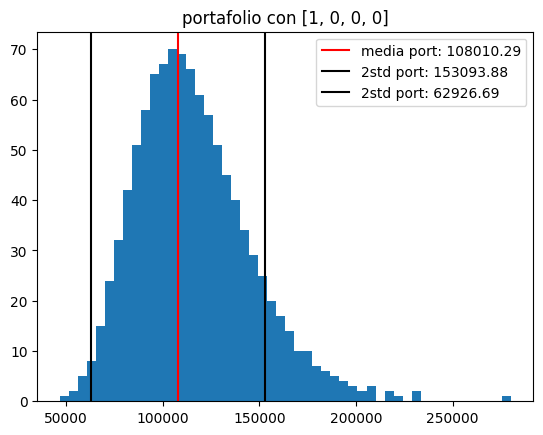

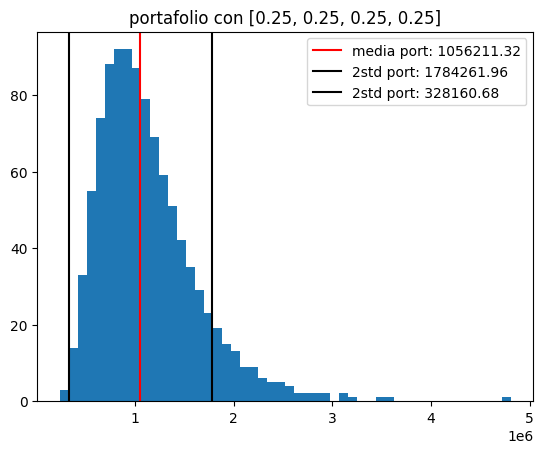

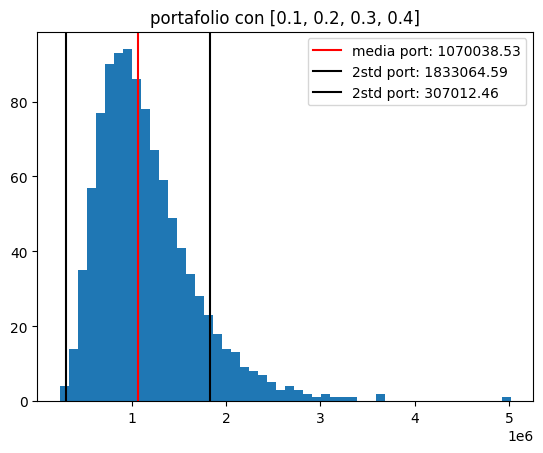

In [125]:
Vo = 100_000
for ws in portafolios.values():
    num_acciones = []
    # CANTIDAD DE ACCIONES POR PORTAFOLIO Y ACCIÓN
    for w,so in zip(ws, So):
        num_acciones.append((w*Vo)/so)
    valores = np.tensordot(num_acciones, precios_sim,axes=1 )
    plt.figure()
    plt.title(f'portafolio con {str(ws)}')
    plt.axvline(x= np.mean(valores), color= 'red', label= f'media port: { np.mean(valores):.2f}')
    plt.axvline(x= np.mean(valores)+2*np.std(valores), color = 'black', label = f'2std port: { np.mean(valores)+2*np.std(valores):.2f}')
    plt.axvline(x= np.mean(valores)-2*np.std(valores), color = 'black', label = f'2std port: { np.mean(valores)-2*np.std(valores):.2f}')

    plt.legend()
    plt.hist(valores[1], bins = 50)
    plt.show()


## MATRIZ DE CORRELACIONES

En la vida real las acciones no se mueven cada quien por su lado: si al sector tech le da gripa, a varias les da tos al mismo tiempo. Por eso ahora vamos a armar la matriz de correlaciones entre tres gigantes tecnológicos: Apple (AAPL), Microsoft (MSFT) y Nvidia (NVDA).

### Bajando datos frescos de Yahoo Finance
En la siguiente celda descargamos 1 año de precios diarios de cierre para AAPL, MSFT y NVDA, y calculamos sus rendimientos logarítmicos diarios (new_rend).

In [126]:
new_tickers = ['AAPL', 'MSFT', "NVDA"]
new_prices = yf.download(new_tickers, period='1Y', interval='1d', progress=False)['Close'].dropna()
new_rend = (np.log(new_prices)).diff().dropna()

### Calculando la matriz de correlación
Con .corr().values sacamos qué tan conectadas están las 3 acciones entre sí. En la diagonal principal siempre hay puros 1 (porque cada acción está 100% correlacionada consigo misma), y los demás números nos dicen qué tanto se acompañan cuando suben o bajan.

In [127]:
corr= new_rend.corr().values
corr

array([[1.        , 0.15549121, 0.05999286],
       [0.15549121, 1.        , 0.23344215],
       [0.05999286, 0.23344215, 1.        ]])

### La receta mágica para simular activos correlacionados (Cholesky)
Para que nuestra simulación respete cómo se mueven juntas las acciones, seguimos estos 4 pasos:
1. Calculamos la matriz de covarianzas/correlaciones $\Sigma$.
2. Le aplicamos la descomposición de Cholesky para partirla en una matriz triangular $L$ tal que $LL^\top = \Sigma$.
3. Generamos ruidos aleatorios independientes $\epsilon \sim \mathcal{N}(0,I)$.
4. Multiplicamos $L\epsilon$ para "contagiarles" la correlación real a nuestros números aleatorios ($Z$).

En la celda de abajo empezamos viendo cómo luce la matriz de covarianzas escalada (Sigma).

In [128]:
Sigma= new_rend.cov()*np.sqrt(252)
Sigma

Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,0.003949,0.000826,0.000366
MSFT,0.000826,0.007152,0.001916
NVDA,0.000366,0.001916,0.009419


### Aplicando Cholesky para 10,000 simulaciones
Aquí hacemos la magia del paso 2, 3 y 4: definimos M = 10000 simulaciones, sacamos la matriz de Cholesky L a partir de nuestra matriz de correlaciones, inventamos 10,000 tríos de números normales independientes (epsilon) y los multiplicamos por L (np.dot(L, epsilon)). Al final trasponemos Z para que nos quede una tabla de 10,000 filas por 3 columnas con choques aleatorios ya correlacionados.

In [129]:
M=10000
L= np.linalg.cholesky(corr)
epsilon= np.random.normal(0,1,[3,M])
Z= np.dot(L,epsilon)
Z=Z.T

$$S_{T,i}= S_{0,i} \exp\left(\left(\mu_i-\frac{\sigma _i^2}{2}\right)T+\sigma _i\sqrt{T}Z\right)$$

### Sacando medias y volatilidades del nuevo trío
Antes de meter todo a la fórmula del precio final $S_{T,i}$, en esta celda calculamos la volatilidad anualizada (sigmas) y el rendimiento promedio diario (mus) de Apple, Microsoft y Nvidia.

In [130]:
sigmas = np.std(new_rend, axis = 0) * np.sqrt(252)
mus= np.mean(new_rend, axis=0)


### Simulando los 10,000 precios finales correlacionados
Aquí anualizamos las medias (mus * 252) y recorremos un ciclo para las 3 acciones (AAPL, MSFT, NVDA). A cada una le aplicamos la fórmula del Movimiento Browniano Geométrico a 1 año (T=1) usando su columna correspondiente de choques correlacionados Z[:, i]. Al final guardamos todo en Sts, que tiene las 10,000 simulaciones de precios finales para las 3 empresas.

In [131]:
Sts = []

# Anualizamos mu para ser consistentes con T=1 y sigmas anualizada
mus_anual = mus * 252  

for i in range(3):
    S0 = new_prices.iloc[-1].iloc[i]
    S_T = S0 * np.exp((mus_anual.iloc[i] - 0.5 * sigmas.iloc[i]**2) * 1 + sigmas.iloc[i] * np.sqrt(1) * Z[:, i])
    Sts.append(S_T)

Sts = np.array(Sts)  # shape: (3, 10000)
Sts

array([[482.26884017, 385.02089634, 598.50894261, ..., 687.27624516,
        273.73549521, 397.47374076],
       [492.5196851 , 360.06958293, 486.22226903, ..., 662.19917301,
        431.32750572, 364.28347557],
       [152.06779486, 165.65177403, 151.10931197, ..., 180.85631557,
        134.59654121, 191.10465188]], shape=(3, 10000))

## Valuación y Gráficas de los Portafolios Correlacionados
Aquí creamos una función súper práctica llamada valorar_port. En lugar de contar acción por acción, calcula el rendimiento relativo de cada activo (precios / S0), lo multiplica por los pesos del portafolio (W) con un producto punto y lo escala por la inversión inicial (V0 = 100,000). Rápido y limpio.

In [132]:
def valorar_port(precios, W, S0, V0=100_000):
    S0 = np.asarray(S0)  
    W = np.asarray(W)    

    relativos = precios / S0[:, None]
    
    valores = V0 * np.dot(W, relativos) 
    return valores

### Probando 3 nuevos portafolios y sacando su PnL (Ganancia o Pérdida)
Definimos 3 combinaciones de pesos (P1, P2 y P3) para nuestras 3 acciones tecnológicas. Luego usamos valorar_port para ver cuánto valdría cada portafolio al final del año en los 10,000 escenarios, y le restamos los $100,000 iniciales para obtener el PnL (PnL_corr), o sea, cuánto dinero ganamos o perdimos netamente en cada simulación.

In [133]:
S0_vec = new_prices.iloc[-1].values 

nuevos_portafolios = {
    'P1': [1.0, 0.0, 0.0],
    'P2': [0.33, 0.33, 0.34],
    'P3': [0.2, 0.4, 0.4]
}

valores_corr = {}
PnL_corr = {}

for nombre, W in nuevos_portafolios.items():
    valores = valorar_port(Sts, W, S0_vec, V0=100_000)
    valores_corr[nombre] = valores
    PnL_corr[nombre] = valores - 100_000  # PnL = Valor_T - Inversión_Inicial

### Graficando los resultados de cada portafolio
Recorremos los resultados de P1, P2 y P3, les sacamos su ganancia promedio (media) y su desviación estándar (desv), y dibujamos un histograma para cada uno con su línea roja en el promedio. Así podemos comparar de un vistazo cuál portafolio gana más en promedio y cuál tiene la campana más ancha (más riesgo).

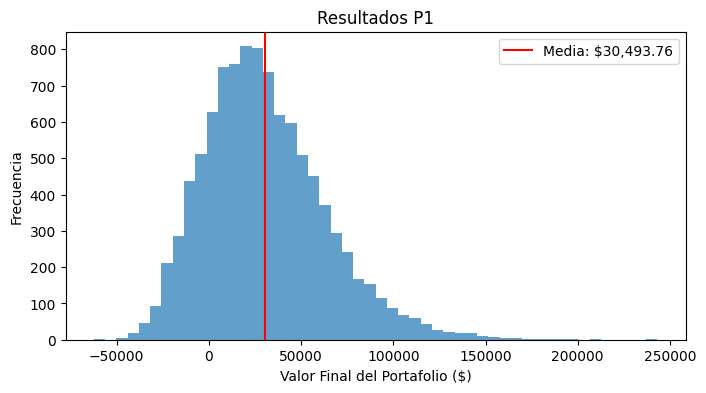

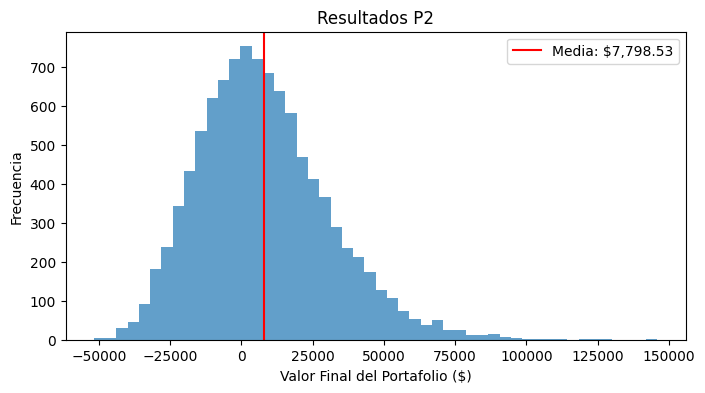

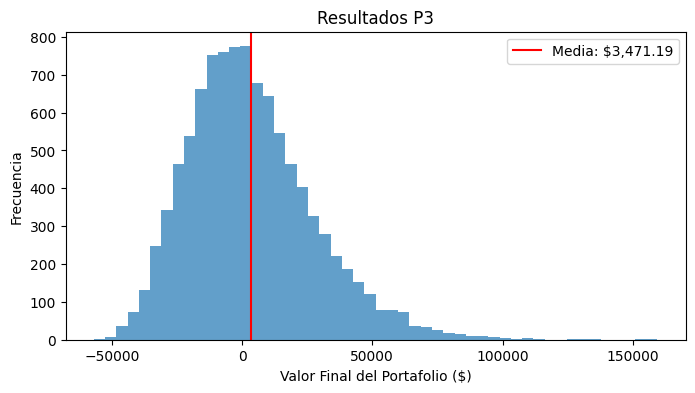

In [134]:
for nombre, val in PnL_corr.items():
    media = np.mean(val)
    desv = np.std(val)
    
    plt.figure(figsize=(8, 4))
    plt.title(f'Resultados {nombre}')
    plt.axvline(x=media, color='red', label=f'Media: ${media:,.2f}')

    
    plt.hist(val, bins=50, alpha=0.7)
    plt.xlabel('Valor Final del Portafolio ($)')
    plt.ylabel('Frecuencia')
    plt.legend()
    plt.show()

# VaR y CVaR (Midiendo el miedo)

In [142]:
def plot_VaR(VaR, cVar, serie, nombre):
    plt.figure(figsize=(10,4))
    plt.title(nombre)

    counts, bins, patches = plt.hist(serie, bins=100, density=True, alpha=0.7, color='b', label = 'ALPHA: .05')

    for patch, left_edge in zip(patches, bins[:-1]):
        if left_edge <= VaR:
            patch.set_facecolor('r')

    plt.axvline(x=VaR, color='r', linestyle='dashed', label=f'VaR: ${VaR:.2f}')
    plt.axvline(x=cVar, color='g', linestyle='dashed', label=f'CVaR: ${cVar:.2f}')
    plt.axvline(x=np.mean(serie), color='k', linestyle='dashed', label=f'Media: ${np.mean(serie):.2f}')
    plt.legend()
    plt.show()

### Calculando y graficando el riesgo de cada portafolio
En este ciclo recorremos las ganancias/pérdidas (PnL_corr) de cada uno de nuestros 3 portafolios:
1. Sacamos de un jalón el percentil 5 (VaR_5) y los tres cuartiles (Q1, Q2, Q3) con np.percentile.
2. Filtramos todos los escenarios que salieron peores o iguales al VaR_5 y les sacamos el promedio para obtener el CVaR.
3. Imprimimos el reporte completo en pantalla y llamamos a plot_VaR para ver la gráfica con la zona de peligro pintada de rojo.

P1
VaR (95% de confianza) = $-16,403.0916
CVaR (95% de confianza) = $-24,578.5508
Q1 = $7,042.5249
Q2 = $26,501.8741
Q3 = $49,795.0375



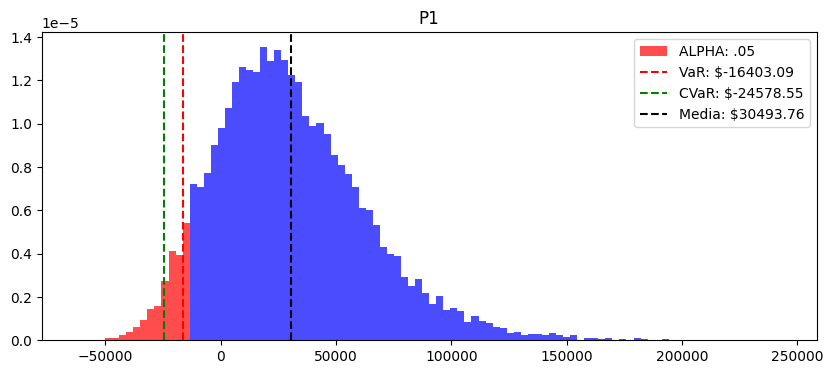

P2
VaR (95% de confianza) = $-25,473.8342
CVaR (95% de confianza) = $-31,537.7562
Q1 = $-8,394.6665
Q2 = $5,341.3335
Q3 = $21,171.9854



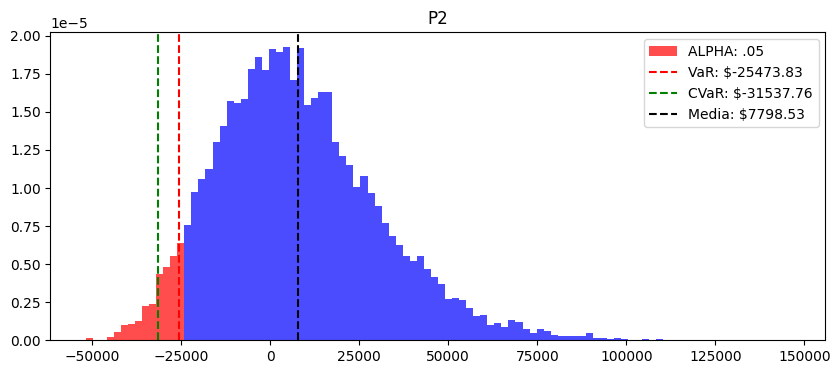

P3
VaR (95% de confianza) = $-30,932.3041
CVaR (95% de confianza) = $-36,691.0698
Q1 = $-13,670.6972
Q2 = $608.2794
Q3 = $17,245.0502



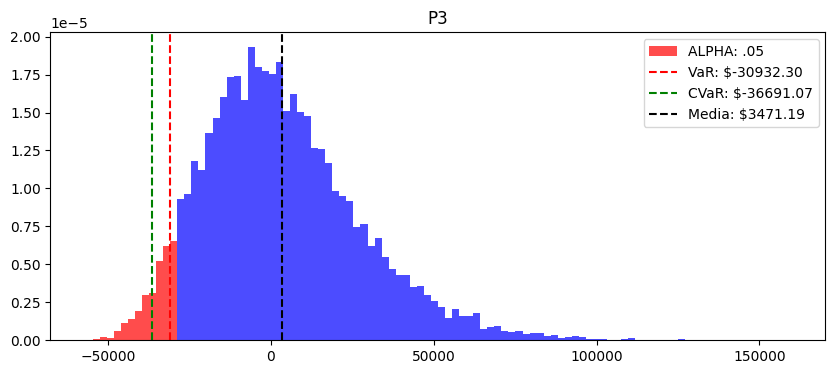

In [143]:
#Percentiles

for i, valores in PnL_corr.items():
    arr = np.asarray(valores)
    
    VaR_5, Q1, Q2, Q3 = np.percentile(arr, [5, 25, 50, 75])
    CVaR = np.mean(arr[arr <= VaR_5])

    print(i)
    print(f"VaR (95% de confianza) = ${VaR_5:,.4f}")
    print(f"CVaR (95% de confianza) = ${CVaR:,.4f}")
    print(f"Q1 = ${Q1:,.4f}")
    print(f"Q2 = ${Q2:,.4f}")
    print(f"Q3 = ${Q3:,.4f}")
    print()

    plot_VaR(VaR_5, CVaR, arr, i)

## Conclusión: 
El VaR nos pone una "línea de advertencia" de cuánto podríamos llegar a perder en un mal año con 95% de confianza, pero el CVaR es el que realmente nos dice qué tan feo se pone el golpe si cruzamos esa línea. Con estos resultados, P1 domina por completo a P2 y P3, ya que ofrece mejores ganancias esperadas en todos sus cuartiles y al mismo tiempo tiene la cola de pérdidas más pequeña.
